# Phishing Website Classifier

## Business understanding

The goal of this project is to develop and evaluate two machine learning classifiers, a decision tree and a random forest, to predict whether a website is legitimate or a phishing website. The models are built using the Phishing Websites dataset from the UCI Machine Learning Repository, which contains information about websites that can be used to distinguish between the two classes.  

The project is divided into two parts. The first part focuses on developing a decision tree classifier that predicts whether a website is a phishing site or not, and provides human-readable classification rules. These rules are also translated into written instructions for identifying a potential phishing website. The goal of the second part is to develop a random forest classifier and investigate whether it can improve predictive performance compared with the decision tree.  

The models are evaluated to assess how reliably they classify websites. The results are used to compare model performance and consider the potential for automating phishing detection. Such a system could help warn users when they are about to visit a potentially malicious website.

## Data Understanding

The dataset contains 30 input variables (indices 0-29) and one target variable `result`. All variables are printed in the next cell. The `result` variable indicates whether a website is a phishing site or a legitimate site. Value -1 means phishing site and value 1 legitimate site.  

All variables are represented as integers. The role of each input variable is Feature, and the role of the target variable is Target.

According to the the UCI Machine Learning Repository, there are no missing values in the dataset. This assignment uses scikit-learn library, and the decision tree classifier works with numerical variables. Since all of the variables are already numerical, no type conversions are needed. Also, no normalization is needed because the decision tree is processing each of the variables individually and does not require features to be on the same scale.  

First, we load the dataset and display variable information.

In [1]:
from ucimlrepo import fetch_ucirepo 
  
# Fetch dataset 
phishing_websites = fetch_ucirepo(id=327) 
  
# Data (as pandas dataframes) 
X = phishing_websites.data.features 
y = phishing_websites.data.targets 
  
# Variable information 
print(phishing_websites.variables) 

                          name     role     type demographic description  \
0            having_ip_address  Feature  Integer        None        None   
1                   url_length  Feature  Integer        None        None   
2           shortining_service  Feature  Integer        None        None   
3             having_at_symbol  Feature  Integer        None        None   
4     double_slash_redirecting  Feature  Integer        None        None   
5                prefix_suffix  Feature  Integer        None        None   
6            having_sub_domain  Feature  Integer        None        None   
7               sslfinal_state  Feature  Integer        None        None   
8   domain_registration_length  Feature  Integer        None        None   
9                      favicon  Feature  Integer        None        None   
10                        port  Feature  Integer        None        None   
11                 https_token  Feature  Integer        None        None   
12          

Let's check the unique values of the input values. Each of the variables are numerical.

In [2]:
for col in X.columns:
    print(f"{col}: {X[col].unique()}")

having_ip_address: [-1  1]
url_length: [ 1  0 -1]
shortining_service: [ 1 -1]
having_at_symbol: [ 1 -1]
double_slash_redirecting: [-1  1]
prefix_suffix: [-1  1]
having_sub_domain: [-1  0  1]
sslfinal_state: [-1  1  0]
domain_registration_length: [-1  1]
favicon: [ 1 -1]
port: [ 1 -1]
https_token: [-1  1]
request_url: [ 1 -1]
url_of_anchor: [-1  0  1]
links_in_tags: [ 1 -1  0]
sfh: [-1  1  0]
submitting_to_email: [-1  1]
abnormal_url: [-1  1]
redirect: [0 1]
on_mouseover: [ 1 -1]
rightclick: [ 1 -1]
popupwindow: [ 1 -1]
iframe: [ 1 -1]
age_of_domain: [-1  1]
dnsrecord: [-1  1]
web_traffic: [-1  0  1]
page_rank: [-1  1]
google_index: [ 1 -1]
links_pointing_to_page: [ 1  0 -1]
statistical_report: [-1  1]


The input variables have either values -1 and 1, or -1, 0, and 1. According to *Phishing Websites Features*, from the UCI Machine Learning Repository, the values represent categories based on feature-specific classification rules. However, the document does not specify precisely how these categories are encoded numerically for each feature.

## Data Preparation

No data preparation was required, as the dataset was already suitable for the selected machine learning algorithms. The input features and target variable were used in their original form.

## Part 1. Decision tree

### Modeling
Next, the dataset is split into training and test sets. The classifier is then trained on the training set and evaluated on the test set.

In [3]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree 

# Extract test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=22)

# Print the number of samples and the dataset size
print(len(X))
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

11055
(8291, 30) (2764, 30) (8291, 1) (2764, 1)


The dataset contains 11,055 samples, of which 8,291 are used for training and 2,764 for testing.

A decision tree classifier is created and trained. The training data is split into separate training and validation sets to identify the best-performing model without using the test data.

In [4]:
# Split the training set into training and validation sets
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_train, y_train, test_size = 0.20, random_state=22)

#### Hyperparameter tuning

I first tried cost-complexity pruning by adjusting the `ccp_alpha` parameter to control the size of the decision tree. I tested the values 0, 0.001, 0.005, 0.01, and 0.02. The highest accuracy was achieved with ccp_alpha = 0, indicating that pruning did not improve the model's performance in these experiments. With ccp_alpha = 0, the accuracy on the validation set was 0.959.

Therefore, I decided not to apply pruning and instead limit the tree's depth using the `max_depth` parameter.   

Different values of `max_depth` are tested to find which one gives the highest accuracy on the validation set.

In [5]:
print("depth  train accuracy  test accuracy")
for i in range(1, 11):
    model = DecisionTreeClassifier(random_state=22, max_depth = i)
    model.fit(X_train2, y_train2)
    print(f"{i}      {model.score(X_train2, y_train2):.5f}         {model.score(X_test2, y_test2):.5f}")

depth  train accuracy  test accuracy
1      0.89264         0.89331
2      0.90998         0.90898
3      0.91194         0.90295
4      0.92189         0.91923
5      0.92747         0.91561
6      0.93471         0.92345
7      0.93878         0.92948
8      0.94466         0.93249
9      0.95280         0.93852
10      0.95944         0.94876


Among the tested values from 1 to 10, a depth of 10 achieved the highest accuracy. However, to keep the decision tree small and easy to interpret, as required by the assignment, some accuracy must be sacrificed. Therefore, a depth of 4 is selected, achieving an accuracy of 0.922 on the validation set.  

Next, the decision tree is created, trained and visualized.

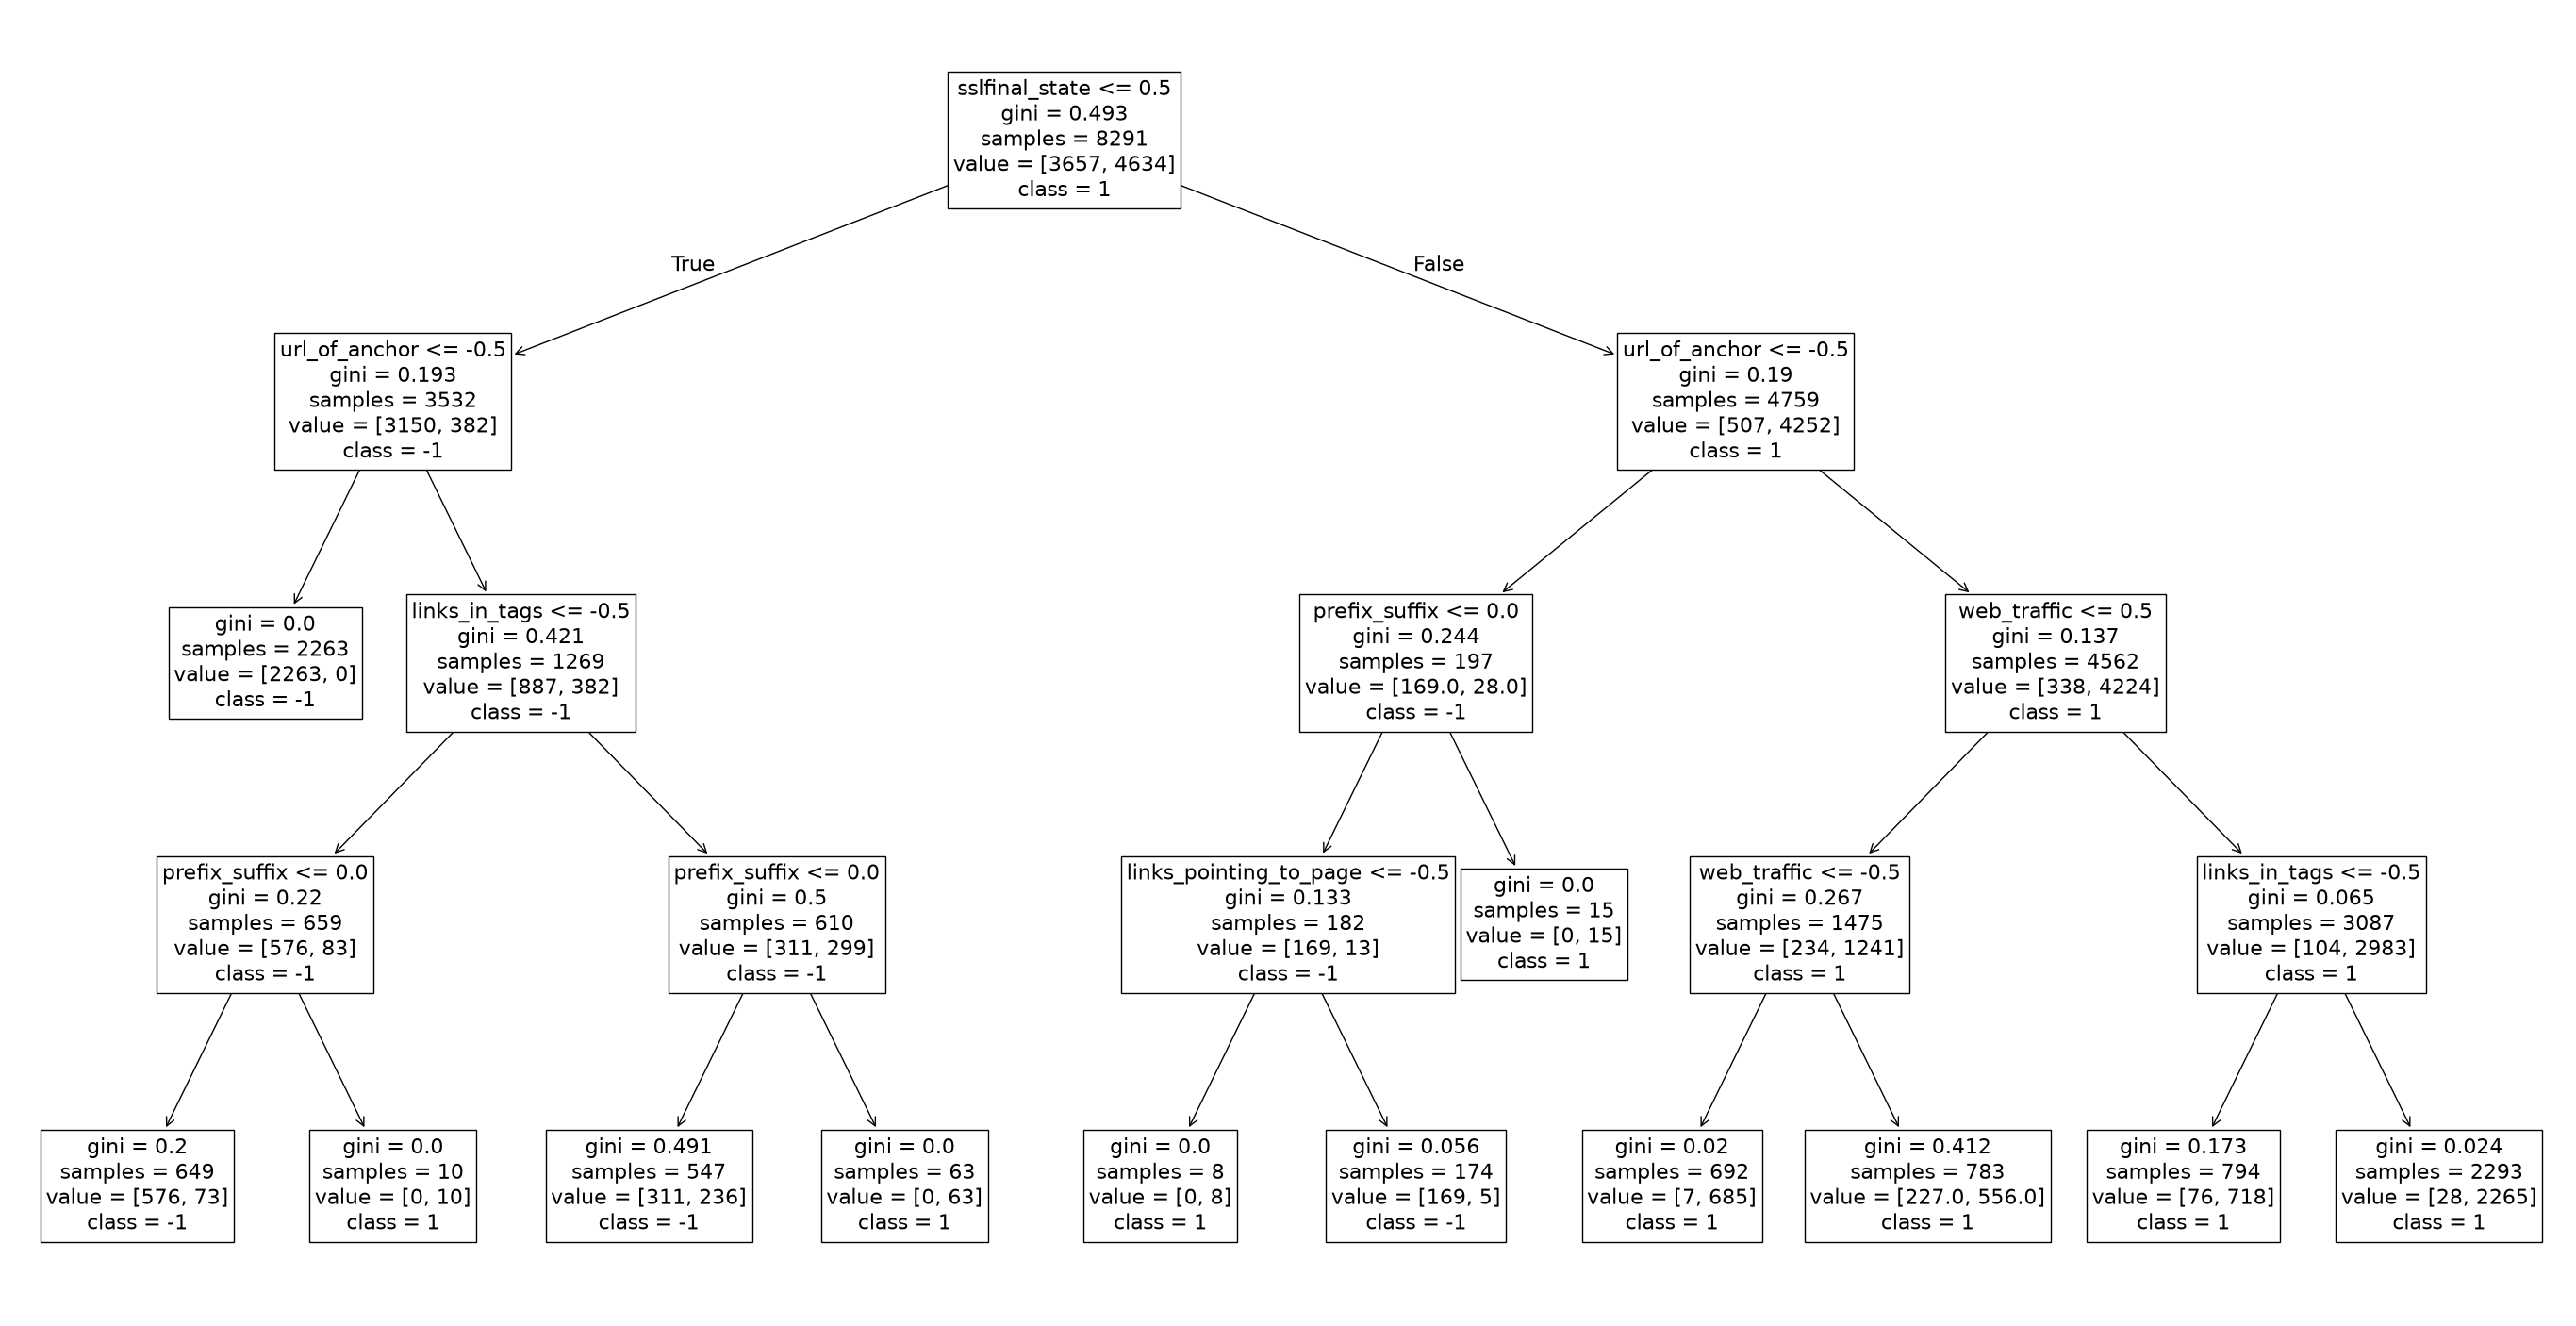

In [6]:
model = DecisionTreeClassifier(random_state=22, max_depth=4)
model.fit(X_train, y_train) # Train the model

# Display the model
fig = plt.figure(figsize = (35, 18))
plot_tree(
    model, 
    feature_names = X.keys(), 
    class_names = ['-1', '1'], 
    fontsize = 16, 
)

plt.show()

Each internal node represents a decision based on a feature, and the branches show the possible outcomes: true on the left and false on the right. The leaf nodes show the predicted class. Limiting the tree depth to 4 makes the model smaller and easier to read.

### Evaluation
The model is evaluated using the test set. A confusion matrix is plotted, and the evaluation metrics (accuracy, precision, and recall) are calculated.

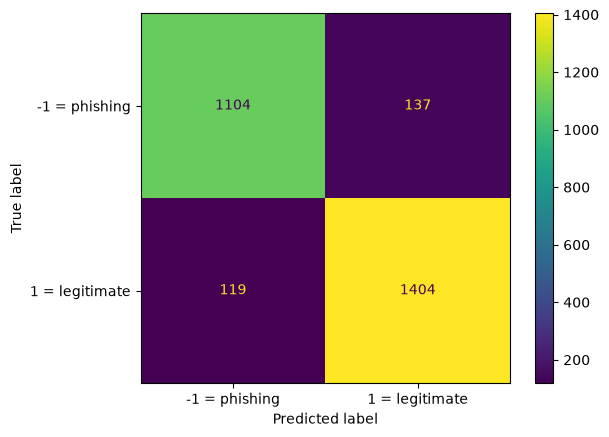

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
preds = model.predict(X_test)

# Visualized confusion matrix
cm = confusion_matrix(y_test, preds)
cmd = ConfusionMatrixDisplay(cm, display_labels=['-1 = phishing','1 = legitimate'])
cmd.plot()

In [8]:
# Check that the confusion matrix labels are in the correct order
import numpy as np
print(np.unique(y))

[-1  1]


The labels match the class values in the dataset: -1 is a phishing website and 1 is a legitimate website.  

Next, evaluation metrics are calculated.  

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

print(f"Accuracy: {accuracy_score(y_test, preds):.3f}")
print(f"Precision: {precision_score(y_test, preds):.3f}")
print(f"Recall: {recall_score(y_test, preds):.3f}")

Accuracy: 0.907
Precision: 0.911
Recall: 0.922


The model's accuracy is 0.907, meaning that it correctly classified 90.7% of the samples. The precision is 0.911, so 91.1% of the websites predicted as phishing websites were actually phishing websites. The recall is 0.922, meaning that the model correctly identified 92.2% of all actual phishing websites.

The confusion matrix shows that 1,104 phishing websites were correctly classified, while 137 were incorrectly classified as legitimate websites. In addition, 1,404 legitimate websites were correctly classified, while 119 were incorrectly classified as phishing websites.

The results show that there is still room for improvement in the decision tree classifier. In particular, the model could be improved to identify more phishing websites correctly and reduce the number of phishing websites classified as legitimate.

#### Instructions for identifying a phishing website

The following instructions are based on the decision tree visualization. The numerical thresholds correspond to the feature values in the dataset. For example, sslfinal_state <= 0.5 includes the values -1 and 0.  

Go through the steps one by one and follow the instructions to move to the specified step when asked. Steps 4 and 5 contain exactly the same rules but occur in different branches of the decision tree.  

1. Check sslfinal_state:
   - If sslfinal_state <= 0.5, go to step 2.
   - If sslfinal_state > 0.5, go to step 6.

2. Check url_of_anchor:
   - If url_of_anchor <= -0.5, the website is classified as a phishing website (class -1).
   - If url_of_anchor > -0.5, go to step 3.

3. Check links_in_tags:
   - If links_in_tags <= -0.5, go to step 4.
   - If links_in_tags > -0.5, go to step 5.

4. Check prefix_suffix:
   - If prefix_suffix <= 0.0, the website is classified as a phishing website (class -1).
   - If prefix_suffix > 0.0, the website is classified as a legitimate website (class 1).

5. Check prefix_suffix:
   - If prefix_suffix <= 0.0, the website is classified as a phishing website (class -1).
   - If prefix_suffix > 0.0, the website is classified as a legitimate website (class 1).

6. If sslfinal_state > 0.5, check url_of_anchor:
   - If url_of_anchor <= -0.5, go to step 7.
   - If url_of_anchor > -0.5, go to step 9.

7. Check prefix_suffix:
   - If prefix_suffix <= 0.0, go to step 8.
   - If prefix_suffix > 0.0, the website is classified as a legitimate website (class 1).

8. Check links_pointing_to_page:
   - If links_pointing_to_page <= -0.5, the website is classified as a legitimate website (class 1).
   - If links_pointing_to_page > -0.5, the website is classified as a phishing website (class -1).

9. If url_of_anchor > -0.5, check web_traffic:
   - If web_traffic <= 0.5, go to step 10.
   - If web_traffic > 0.5, go to step 11.

10. The website is classified as a legitimate website (class 1), regardless of the web_traffic value. Both branches lead to the same classification.

11. If web_traffic > 0.5, the website is classified as a legitimate website (class 1), regardless of the links_in_tags value.

## Osa 2. Random forest

### Modeling
The same training and test sets as before are used. Cross-validation is performed on the training set to select the best hyperparameter values based on model performance. 

A random forest classifier with 100 trees is used. The `max_samples` and `max_features` parameters are tested with values of 0.5, 0.7, 0.85, and 1.0. Ten-fold cross-validation is used to compare the performance of each parameter combination and identify the best-performing model.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

# Convert y_train into a one-dimensional array
y_train = y_train.values.ravel()

print("max_samples  max_features  mean score")
for max_samples in [0.5, 0.7, 0.85, 1.0]:
    for max_features in [0.5, 0.7, 0.85, 1.0]:
        model = RandomForestClassifier(
            n_estimators=100,
            bootstrap=True,
            max_samples=max_samples,
            max_features=max_features,
            random_state=22
        )

        scores = cross_val_score(
            model, 
            X_train, 
            y_train,
            cv=10 # Fold count
        )

        # Print the mean cross-validation score for each parameter combination
        print(f"{max_samples}          {max_features}          {scores.mean():.4f}")

max_samples  max_features  mean score
0.5          0.5          0.9685
0.5          0.7          0.9677
0.5          0.85          0.9674
0.5          1.0          0.9676
0.7          0.5          0.9698
0.7          0.7          0.9703
0.7          0.85          0.9689
0.7          1.0          0.9695
0.85          0.5          0.9705
0.85          0.7          0.9695
0.85          0.85          0.9691
0.85          1.0          0.9696
1.0          0.5          0.9690
1.0          0.7          0.9702
1.0          0.85          0.9700
1.0          1.0          0.9698


The best result, a mean accuracy of 0.9705 from 10-fold cross-validation, was achieved with `max_samples` set to 0.85 and `max_features` set to 0.5. These values are used to train the final model. The same `random_state` value (22) is used as in the decision tree to ensure reproducibility.

In [11]:
model = RandomForestClassifier(
            n_estimators=100,
            bootstrap=True,
            max_samples=0.85,
            max_features=0.5,
            random_state=22
        )

# Train the model
model.fit(X_train, y_train)

,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",22
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",0.85
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of th

### Evaluation

Confusion matrix is visualized and evaluation metrics are calculated.

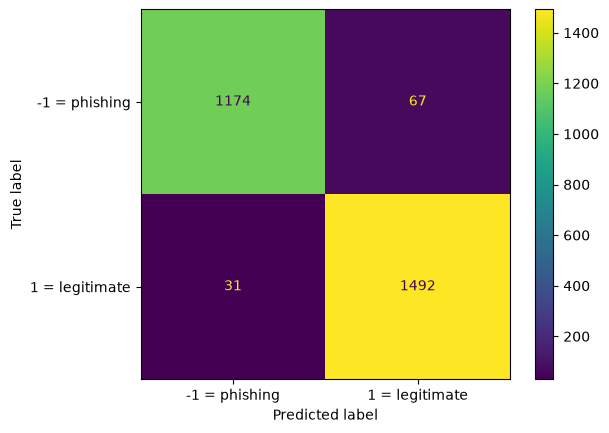

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

y_pred = model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
cmd = ConfusionMatrixDisplay(cm, display_labels=['-1 = phishing','1 = legitimate'])
cmd.plot()

Classification report is printed.

In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          -1       0.97      0.95      0.96      1241
           1       0.96      0.98      0.97      1523

    accuracy                           0.96      2764
   macro avg       0.97      0.96      0.96      2764
weighted avg       0.96      0.96      0.96      2764



Feature importances are calculated to identify which variables contribute most to the classification of phishing websites.

In [14]:
# Feature importances
for i in range(len(X_train.columns)):
    print(f"{X_train.columns[i]}  {model.feature_importances_[i]:.5f}")

having_ip_address  0.01014
url_length  0.00743
shortining_service  0.00308
having_at_symbol  0.00378
double_slash_redirecting  0.00200
prefix_suffix  0.03067
having_sub_domain  0.03793
sslfinal_state  0.48550
domain_registration_length  0.01035
favicon  0.00255
port  0.00149
https_token  0.00433
request_url  0.01367
url_of_anchor  0.20671
links_in_tags  0.03494
sfh  0.01200
submitting_to_email  0.00416
abnormal_url  0.00218
redirect  0.00392
on_mouseover  0.00218
rightclick  0.00100
popupwindow  0.00333
iframe  0.00128
age_of_domain  0.01306
dnsrecord  0.01033
web_traffic  0.05145
page_rank  0.00813
google_index  0.01113
links_pointing_to_page  0.01786
statistical_report  0.00340


The classifier achieved an accuracy of 0.96 on the separate test set using the hyperparameter values `max_samples=0.85` and `max_features=0.5`. These values achieved the best mean accuracy of 0.9705 in the 10-fold cross-validation experiments.  

Compared with the single decision tree, the random forest classifier performs better at identifying phishing websites. The random forest achieved an accuracy of 0.96, while the decision tree in Part 1 achieved an accuracy of 0.91. The random forest correctly classified 1,174 phishing websites, while 67 phishing websites were incorrectly classified as legitimate. In addition, 31 legitimate websites were incorrectly classified as phishing websites, while 1,492 legitimate websites were correctly classified. The recall for phishing websites (class -1) was 0.95, meaning that the model correctly identified approximately 95% of the phishing websites in the test set.  

Based on the random forest feature importance scores, the most important feature is `sslfinal_state`, with an importance score of 0.49. This means that it has the largest relative importance in the model's predictions. The second most important feature is `url_of_anchor`, with a score of 0.21. The remaining features have considerably lower importance scores.  

Overall, the random forest performed better than the decision tree on the test set in terms of accuracy. However, the comparison should take into account that the decision tree in Part 1 was limited to a maximum depth of 4 to improve readability, while the trees in the random forest in Part 2 were not limited in depth.